# 50km - FK - no GM

In [3]:
import os
import numpy as np
from MITgcmutils import mds
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/'
path_run = 'run/'

# 4651488 - 3.68 years
import pickle
nStep1, nStep2, dS = 0, 2928960, 25920
time_index = np.arange(nStep1, nStep2 + 1, dS, dtype=int)
num_data = time_index.size
print("Total data number is:", num_data)
fout = '50km_FK_noGM.pkl'
# Load the saved data
iters_done, eke_list = [], []
if os.path.exists(fout):
    with open(fout, 'rb') as f:
        obj = pickle.load(f)
    if isinstance(obj, list):            # your original format
        eke_list = list(obj)
        iters_done = list(time_index[:len(eke_list)])  # best-effort align
    else:                                # new dict format
        iters_done = list(obj.get("iters", []))
        eke_list   = list(obj.get("eke", []))

done_set = set(iters_done)
print(f"Already saved: {len(eke_list)} records.")

# --- process only the missing iterations ---
added = 0
for it in time_index:
    if it in done_set:
        continue

    U = mds.rdmds(os.path.join(path_scratch, path_MITgcm, path_run, 'U'), it)
    V = mds.rdmds(os.path.join(path_scratch, path_MITgcm, path_run, 'V'), it)
    if U is None or V is None:
        # file not written yet; skip now, catch it next run
        continue

    u0 = U[0]  # surface level
    v0 = V[0]
    u0p = u0 - np.mean(u0)
    v0p = v0 - np.mean(v0)
    eke_mean = float(np.mean(0.5 * (u0p**2 + v0p**2)))

    eke_list.append(eke_mean)
    iters_done.append(it)
    done_set.add(it)
    added += 1

    # tiny checkpoint every 100 new points
    if added % 100 == 0:
        with open(fout, 'wb') as f:
            pickle.dump({"iters": iters_done, "eke": eke_list}, f)
        print(f"Checkpoint: {len(eke_list)} total (last iter {it}).")

# --- final save ---
with open(fout, 'wb') as f:
    pickle.dump({"iters": iters_done, "eke": eke_list}, f)

print(f"Saved {len(eke_list)} records total. Added {added} this run.")


Total data number is: 114
Already saved: 86 records.
Saved 114 records total. Added 28 this run.


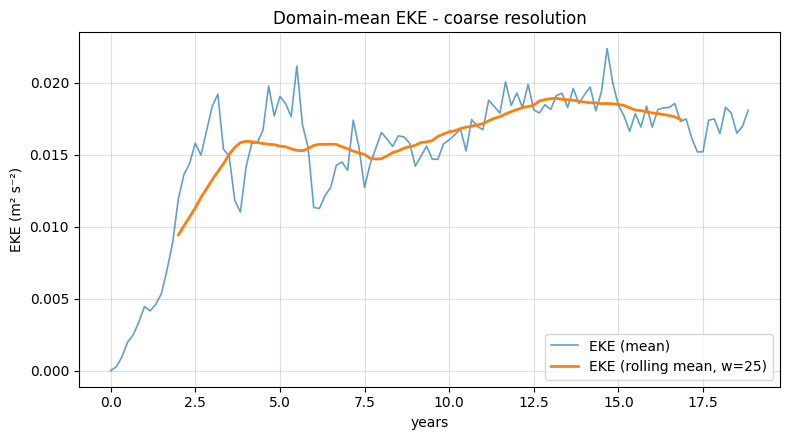

In [4]:
import os, pickle
import numpy as np
import matplotlib.pyplot as plt

fout = '50km_FK_noGM.pkl'  # change to absolute path if needed

# --- load & normalize format ---
with open(fout, 'rb') as f:
    obj = pickle.load(f)

if isinstance(obj, list):
    raise ValueError("This file is the old plain list. Re-run your saving script once to upgrade it to a dict with 'iters' and 'eke'.")
else:
    iters = np.array(obj["iters"], dtype=int)
    eke   = np.array(obj["eke"], dtype=float)

# sort & deduplicate just in case
order = np.argsort(iters)
iters = iters[order]
eke   = eke[order]

# --- OPTIONAL: convert iterations to model time (days) ---
# Set your model deltaT (seconds per time step) if you want a time axis.
# For example, if deltaT = 300 s: one iteration = 300 s.
# deltaT = 300
# t_days = iters * deltaT / 86400.0
# x = t_days; x_label = "Model time (days)"
x = iters; x_label = "years"

# --- OPTIONAL: a light rolling mean to smooth wiggles ---
def rolling_mean(a, w=20):
    if w <= 1: return a
    # simple centered rolling; edges are left NaN
    pad = w // 2
    out = np.full_like(a, np.nan, dtype=float)
    csum = np.cumsum(np.insert(a, 0, 0.0))
    out[pad:len(a)-pad] = (csum[w:] - csum[:-w]) / w
    return out

eke_smooth = rolling_mean(eke, w=25)  # tweak window as you like
x = x * 200 / (86400 * 360)
# --- plot ---
plt.figure(figsize=(8,4.5))
plt.plot(x[:], eke[:], lw=1.2, alpha=0.7, label="EKE (mean)")
plt.plot(x, eke_smooth, lw=2.0, label="EKE (rolling mean, w=25)")
plt.xlabel(x_label)
plt.ylabel("EKE (m² s⁻²)")  
plt.title("Domain-mean EKE - coarse resolution")
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("50km_FK_no_GM.png", dpi=200)
plt.show()
